In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

Lorenz System Simulator

In [4]:
def simulate_lorenz(sigma=10.0, rho=28.0, beta=8/3, dt=0.01, T=20.0):
    num_steps = int(T / dt)
    x = torch.zeros((num_steps, 3))
    
    x[0, 0] = 1.0
    x[0, 1] = 1.0
    x[0, 2] = 1.0
    
    for t in range(num_steps - 1):
        x_t = x[t]
        
        dx = sigma * (x_t[1] - x_t[0])
        dy = x_t[0] * (rho - x_t[2]) - x_t[1]
        dz = x_t[0] * x_t[1] - beta * x_t[2]

        x[t + 1, 0] = x_t[0] + dt * dx + 0.1 * torch.randn(1)
        x[t + 1, 1] = x_t[1] + dt * dy + 0.1 * torch.randn(1)
        x[t + 1, 2] = x_t[2] + dt * dz + 0.1 * torch.randn(1)

    return x


In [5]:
# Cố định random seed
torch.manual_seed(42)

# Mô phỏng hệ Lorenz
data = simulate_lorenz()

# Kiểm tra dữ liệu
print("Data shape:", data.shape)
print("Data type:", data.dtype)
print("Device:", data.device)

print("\nFirst 5 observations:")
print(data[:5])

print("\nMissing/Invalid values:")
print("NaN count:", torch.isnan(data).sum().item())
print("Inf count:", torch.isinf(data).sum().item())


Data shape: torch.Size([2000, 3])
Data type: torch.float32
Device: cpu

First 5 observations:
tensor([[1.0000, 1.0000, 1.0000],
        [1.0337, 1.2729, 1.0068],
        [1.0806, 1.4269, 0.9745],
        [1.3361, 1.6409, 1.0101],
        [1.3933, 2.0385, 1.0860]])

Missing/Invalid values:
NaN count: 0
Inf count: 0


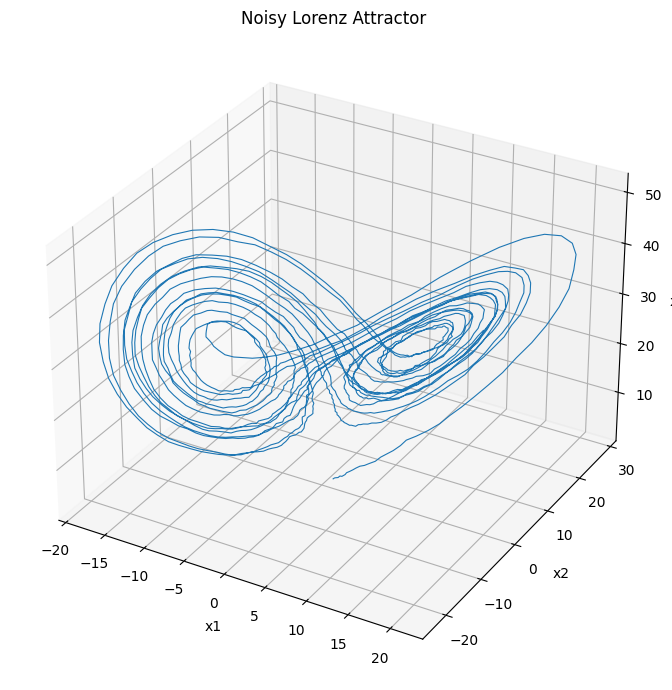

In [6]:
# Chuyển Tensor sang NumPy array
data_np = data.detach().cpu().numpy()

# Tạo biểu đồ 3D
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

# Vẽ quỹ đạo Lorenz
ax.plot(
    data_np[:, 0],
    data_np[:, 1],
    data_np[:, 2],
    linewidth=0.8
)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")
ax.set_title("Noisy Lorenz Attractor")

plt.tight_layout()
plt.show()

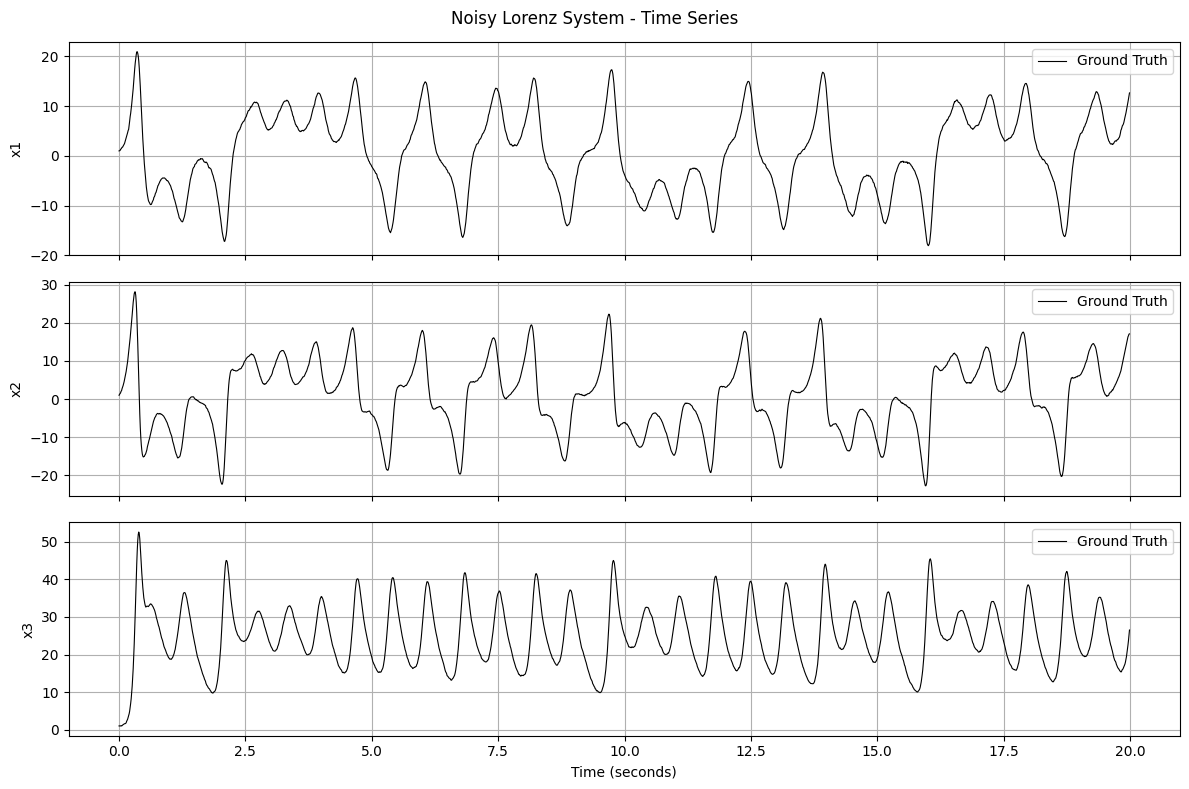

In [8]:

# Tạo trục thời gian
dt = 0.01
time = np.arange(len(data_np)) * dt

# Tạo 3 biểu đồ con
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Vẽ từng biến trạng thái
for i in range(3):
    axes[i].plot(time, data_np[:, i], color = "black", linewidth=0.8, label="Ground Truth")
    axes[i].set_ylabel(f"x{i+1}")
    axes[i].grid(True)
    axes[i].legend()

# Nhãn và tiêu đề
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Noisy Lorenz System - Time Series")

plt.tight_layout()
plt.show()


In [12]:
#sliding window configuration
patch_length = 150
horizon = 5

x_in = []
x_out = []

for i in range(len(data) - patch_length - horizon):
    x_in.append(data[i:i + patch_length])
    x_out.append(data[i + patch_length:i + patch_length + horizon].reshape(-1))

x_in = torch.stack(x_in)
x_out = torch.stack(x_out)

print("Input shape:", x_in.shape)
print("Output shape:", x_out.shape)

Input shape: torch.Size([1845, 150, 3])
Output shape: torch.Size([1845, 15])


lưu dataset

In [14]:
# Xác định thư mục lưu kết quả
cwd = Path.cwd()
if (cwd / "experiments" / "01_lorenz").is_dir():
    output_dir = cwd / "experiments" / "01_lorenz" / "results"
elif cwd.name == "01_lorenz":
    output_dir = cwd / "results"
else:
    raise FileNotFoundError("Không tìm thấy thư mục 01_lorenz")

# Tạo thư mục nếu chưa tồn tại
output_dir.mkdir(parents=True, exist_ok=True)

# Lưu dữ liệu Lorenz
torch.save(
    {
        "data": data,
        "X": x_in,
        "Y": x_out,
        "patch_length": patch_length,
        "horizon": horizon,
        "seed": 42
    },
    output_dir / "lorenz_dataset.pt"
)

print("Dataset saved successfully!")
print("File:", output_dir / "lorenz_dataset.pt")

Dataset saved successfully!
File: c:\Users\Win 11 New\Desktop\pa gk\experiments\01_lorenz\results\lorenz_dataset.pt


In [16]:
# Householder Orthogonalization
def householder_orthogonalization(W):
    Q, _ = torch.linalg.qr(W)
    return Q

# Kiểm tra phép trực giao hóa
W = torch.tensor([
    [1.0, 2.0],
    [3.0, 4.0]
])

Q = householder_orthogonalization(W)

print("Original matrix W:")
print(W)

print("\nOrthogonal matrix Q:")
print(Q)

print("\nQ.T @ Q:")
print(Q.T @ Q)

print("\nIs orthogonal?", torch.allclose(Q.T @ Q, torch.eye(2), atol=1e-6))


Original matrix W:
tensor([[1., 2.],
        [3., 4.]])

Orthogonal matrix Q:
tensor([[-0.3162, -0.9487],
        [-0.9487,  0.3162]])

Q.T @ Q:
tensor([[1.0000e+00, 2.9802e-08],
        [2.9802e-08, 1.0000e+00]])

Is orthogonal? True


In [17]:
import torch.nn as nn

# Strict Stable Koopman Operator
class StrictStableKoopmanOperator(nn.Module):
    def __init__(self, latent_dim, max_spectral_radius=0.99):
        super().__init__()

        self.latent_dim = latent_dim
        self.max_spectral_radius = max_spectral_radius

        self.U_raw = nn.Parameter(
            torch.randn(latent_dim, latent_dim)
        )

        self.V_raw = nn.Parameter(
            torch.randn(latent_dim, latent_dim)
        )

        self.S_unconstrained = nn.Parameter(
            torch.randn(latent_dim)
        )

    def forward(self, z):
        U = householder_orthogonalization(self.U_raw)
        V = householder_orthogonalization(self.V_raw)

        S = torch.sigmoid(self.S_unconstrained) * self.max_spectral_radius

        K = U @ torch.diag(S) @ V.T

        z_next = z @ K.T

        return z_next, K, S
